# SA-CCR Calculator vs Internal Model EAD

Even a bank with its own exposure model has to compute the regulator's standard formula, because that formula sets capital floors, leverage exposure and large-exposure limits. The gap between the two numbers decides which trades are expensive in capital. This notebook builds the standard formula from the rulebook, proves it reproduces the Basel Committee's own examples, and maps where it is most punitive compared with a Monte Carlo model.

**What it does.** It implements the Basel standardised approach for counterparty credit risk (SA-CCR, CRE52) for all five asset classes and validates it against the Basel Committee's worked examples.

It then compares it with an internal-model (IMM) EAD from Monte Carlo on 1,500 interest-rate and FX netting sets.

**Data.** Today's SOFR curve and Treasury volatility (U.S. Treasury, FRED), and USD/EUR, USD/GBP and USD/JPY exchange rates with €STR, SONIA and Japanese 3-month rates (FRED). The multi-asset trade portfolio is synthetic.

**Methods.** A Basel rule engine (supervisory duration, delta, maturity factor, hedging-set aggregation, multiplier, margined and unmargined replacement cost, leverage-ratio exposure).

The IMM side is EEPE from Hull–White rates and correlated GBM FX simulation with the Classical+ collateral model. A linear quantile regression explains the SA-CCR/IMM ratio.

**Key output.** Exact reproduction of the Basel examples (EAD 569, 381 and 5,406), an EAD breakdown by asset class for six netting sets, and a map of when SA-CCR is most conservative compared with the internal model.

## 1. Why SA-CCR matters even for a bank with an internal model

SA-CCR replaced the Current Exposure Method in 2017. For most institutions it is the regulatory EAD for derivatives. Banks with IMM approval still compute it, because it drives:

- the **output floor** (internal-model RWAs cannot fall below 72.5% of the standardised RWAs),
- the **leverage ratio** exposure measure (with special rules on collateral and the multiplier),
- **large exposure** limits and the CVA capital charge under the basic approach (BA-CVA).

For a credit officer, the gap between SA-CCR and the internal model is a business question. A trade that looks cheap under the internal model can consume a lot of standardised capital, and the reverse.

$$
\text{EAD}=\alpha\,\big(\text{RC}+\text{multiplier}\times\text{AddOn}^{\text{aggregate}}\big),\qquad \alpha=1.4
$$

| Component | Unmargined | Margined |
|---|---|---|
| **Replacement cost** | $\max(V-C,\,0)$ | $\max(V-C,\;TH+MTA-NICA,\;0)$ |
| **Maturity factor** | $\sqrt{\min(M,1)/1}$, $M\ge 10$ business days | $\tfrac32\sqrt{MPoR/250}$ |
| **Multiplier** | $\min\Big\{1;\;0.05+0.95\exp\Big(\dfrac{V-C}{2\cdot0.95\cdot\text{AddOn}}\Big)\Big\}$ | same |

**Trade level.** Adjusted notional $d_i$: notional × supervisory duration $SD=\frac{e^{-0.05S}-e^{-0.05E}}{0.05}$ for rates and credit, USD notional of the foreign leg for FX, and market value for equity and commodities. Supervisory delta $\delta_i$ is $\pm1$, or for options $\pm\Phi(\pm d_1)$ at supervisory volatility. Effective notional is $D_i=\delta_i\,d_i\,MF_i$.

**Hedging-set aggregation.**

- **Rates:** per currency, three maturity buckets with partial offset, $EN=\sqrt{D_1^2+D_2^2+D_3^2+1.4D_1D_2+1.4D_2D_3+0.6D_1D_3}$.
- **FX:** per currency pair, $|\sum D|$.
- **Credit and equity:** a one-factor formula across entities, $\sqrt{(\sum\rho_k A_k)^2+\sum(1-\rho_k^2)A_k^2}$.
- **Commodities:** the same formula across commodity types within energy, metals, agriculture and other.

Supervisory factors and correlations are those of CRE52.

## 2. Setup

In [1]:
# --- macOS safety switch (must run before any scientific import)
# Several libraries (PyTorch, LightGBM, scikit-learn, NumPy builds) ship their
# own OpenMP runtime.
# On Apple Silicon two copies in one process can make Jupyter report "the
# kernel crashed".
import os

os.environ.setdefault("KMP_DUPLICATE_LIB_OK", "TRUE")


# --- Standard library
import datetime as dt
import io
import re
import time
import warnings
from pathlib import Path

# --- Third-party
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import requests
from dotenv import find_dotenv, load_dotenv
from fredapi import Fred
from plotly.subplots import make_subplots
import QuantLib as ql
import statsmodels.formula.api as smf
from scipy.optimize import least_squares
from scipy.stats import norm

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

PROJECT_DIR = Path.cwd()
DATA_DIR, OUT_DIR = PROJECT_DIR / "data", PROJECT_DIR / "outputs"
DATA_DIR.mkdir(exist_ok=True)
OUT_DIR.mkdir(exist_ok=True)

load_dotenv(find_dotenv(usecwd=True))
FRED_API_KEY = os.getenv("FRED_API_KEY", "").strip()
if not FRED_API_KEY:
    raise RuntimeError(
        "FRED_API_KEY not found. Create the .env file at the repo root (see"
        " .env.example)."
    )
fred = Fred(api_key=FRED_API_KEY)
BROWSER_HEADERS = {
    "User-Agent": (
        "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) Chrome/130.0"
        " Safari/537.36"
    )
}

ALPHA = 1.4
N_PATHS = 5_000  # Monte Carlo paths for the IMM engine
# random IR/FX netting sets for the SA-CCR vs IMM comparison
N_DESIGNS = 1_500
DT = 1 / 12  # monthly grid; EEPE only needs the first year
MPOR_DAYS = 10
SEED = 21

print(
    f"QuantLib {ql.__version__} · statsmodels · run on"
    f" {dt.date.today():%Y-%m-%d}"
)

QuantLib 1.44 · statsmodels · run on 2026-10-19


In [2]:
# --- Caching helper: every download is stored in data/ and reused for 12 hours
def cached(name, fetch, max_age_hours=12):
    path = DATA_DIR / f"{name}.parquet"
    if (
        path.exists()
        and (time.time() - path.stat().st_mtime) / 3600 < max_age_hours
    ):
        return pd.read_parquet(path)
    try:
        frame = fetch()
        frame.to_parquet(path)
        return frame
    except Exception as err:
        if path.exists():
            print(
                f"⚠️  {name}: download failed ({type(err).__name__}); using"
                " cached copy"
            )
            return pd.read_parquet(path)
        raise


# --- Chart style
PALETTE = [
    "#2a78d6",
    "#eb6834",
    "#1baf7a",
    "#eda100",
    "#e87ba4",
    "#008300",
    "#6250d6",
    "#e34948",
]
INK, INK_2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
STATUS = {"green": "#1baf7a", "amber": "#eda100", "red": "#e34948"}
plt.rcParams.update({
    "figure.facecolor": SURFACE,
    "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": GRID,
    "axes.labelcolor": INK_2,
    "axes.titlecolor": INK,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.grid": True,
    "grid.color": GRID,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "xtick.color": INK_2,
    "ytick.color": INK_2,
    "legend.frameon": False,
    "lines.linewidth": 2.0,
    "font.size": 10,
    "figure.dpi": 110,
    "axes.axisbelow": True,
})


def save_fig(fig, name):
    fig.savefig(OUT_DIR / f"{name}.png", dpi=150, bbox_inches="tight")


def save_dashboard(dash, name):
    """
    Interactive HTML always; static PNG (for GitHub) when kaleido can find
    Chrome.
    """
    dash.write_html(OUT_DIR / f"{name}.html", include_plotlyjs="cdn")
    try:
        dash.write_image(OUT_DIR / f"{name}.png", scale=2)
        print(f"Dashboard saved: outputs/{name}.html and .png")
    except Exception as err:
        print(
            f"Dashboard saved as HTML; PNG skipped ({type(err).__name__}). Run"
            " `plotly_get_chrome` once."
        )


def tenor_label(t):
    return f"{int(round(t * 12))}M" if t < 1 else f"{t:g}Y"


CLASS_COLORS = {
    "IR": PALETTE[0],
    "FX": PALETTE[1],
    "CR": PALETTE[2],
    "EQ": PALETTE[6],
    "CO": PALETTE[3],
}

## 3. The SA-CCR engine

One function per step, so every intermediate number can be inspected and reconciled. That is what a model validator or a regulator asks for. Trades are rows of a DataFrame with a small set of standard fields.

In [3]:
# --- CRE52 supervisory parameters
SF = {
    "IR": 0.005,
    "FX": 0.04,
    "CR": {
        "AAA": 0.0038,
        "AA": 0.0038,
        "A": 0.0042,
        "BBB": 0.0054,
        "BB": 0.0106,
        "B": 0.016,
        "CCC": 0.06,
        "IG index": 0.0038,
        "SG index": 0.0106,
    },
    "EQ": {"single": 0.32, "index": 0.20},
    "CO": {
        "electricity": 0.40,
        "oil_gas": 0.18,
        "metals": 0.18,
        "agricultural": 0.18,
        "other": 0.18,
    },
}
RHO = {
    "CR": {"single": 0.5, "index": 0.8},
    "EQ": {"single": 0.5, "index": 0.8},
    "CO": 0.4,
}
SUP_VOL = {
    "IR": 0.50,
    "FX": 0.15,
    "CR": {"single": 1.0, "index": 0.8},
    "EQ": {"single": 1.2, "index": 0.75},
    "CO": {"electricity": 1.5, "default": 0.7},
}
CO_HEDGING_SET = {
    "electricity": "energy",
    "oil_gas": "energy",
    "metals": "metals",
    "agricultural": "agricultural",
    "other": "other",
}


def supervisory_duration(S, E):
    S, E = np.maximum(S, 0), np.maximum(E, 0)
    return (np.exp(-0.05 * S) - np.exp(-0.05 * E)) / 0.05


def supervisory_vol(tr):
    v = SUP_VOL[tr["asset_class"]]
    if tr["asset_class"] in ("CR", "EQ"):
        return v["index" if tr["is_index"] else "single"]
    if tr["asset_class"] == "CO":
        return v["electricity"] if tr["sub"] == "electricity" else v["default"]
    return v


def supervisory_delta(tr):
    """
    +1/−1 for linear trades (long/short the primary risk factor); Black delta
    at supervisory vol for options.
    """
    if not tr["is_option"]:
        return float(tr["direction"])
    sig, T = supervisory_vol(tr), max(tr["option_T"], 1e-4)
    d1 = (np.log(tr["P"] / tr["K"]) + 0.5 * sig**2 * T) / (sig * np.sqrt(T))
    sign = 1.0 if tr["bought"] else -1.0
    return sign * (
        norm.cdf(d1) if tr["option_type"] == "call" else -norm.cdf(-d1)
    )


def maturity_factor(tr, margined, mpor_days):
    if margined:
        return 1.5 * np.sqrt(mpor_days / 250)
    M = max(tr["M"], 10 / 250)
    return np.sqrt(min(M, 1.0))


def adjusted_notional(tr):
    if tr["asset_class"] in ("IR", "CR"):
        return tr["notional"] * supervisory_duration(tr["S"], tr["E"])
    # FX: USD value of foreign leg; EQ/CO: market value
    return tr["notional"]


def trade_level(trades, margined=False, mpor_days=10):
    t = trades.copy()
    t["SD"] = [
        supervisory_duration(s, e) if ac in ("IR", "CR") else np.nan
        for s, e, ac in zip(t["S"], t["E"], t["asset_class"])
    ]
    t["d"] = t.apply(adjusted_notional, axis=1)
    t["delta"] = t.apply(supervisory_delta, axis=1)
    t["MF"] = t.apply(
        lambda r: maturity_factor(r, margined, mpor_days), axis=1
    )
    t["D"] = t["delta"] * t["d"] * t["MF"]
    return t

In [4]:
def addon_ir(t):
    out = {}
    for ccy, g in t.groupby("sub"):
        bucket = np.select([g["E"] < 1, g["E"] <= 5], [1, 2], 3)
        D = [g.loc[bucket == b, "D"].sum() for b in (1, 2, 3)]
        en = np.sqrt(
            D[0] ** 2
            + D[1] ** 2
            + D[2] ** 2
            + 1.4 * D[0] * D[1]
            + 1.4 * D[1] * D[2]
            + 0.6 * D[0] * D[2]
        )
        out[ccy] = SF["IR"] * en
    return out


def addon_fx(t):
    return {pair: SF["FX"] * abs(g["D"].sum()) for pair, g in t.groupby("sub")}


def addon_single_factor(t, cls):
    """
    Credit and equity: entity add-ons aggregated with the supervisory one-
    factor formula.
    """
    rows = []
    for (entity, is_index), g in t.groupby(["sub", "is_index"]):
        if cls == "CR":
            sf = SF["CR"][g["rating"].iloc[0]]
        else:
            sf = SF["EQ"]["index" if is_index else "single"]
        rows.append(
            (sf * g["D"].sum(), RHO[cls]["index" if is_index else "single"])
        )
    a, rho = np.array(rows).T
    return {"all": np.sqrt((rho * a).sum() ** 2 + ((1 - rho**2) * a**2).sum())}


def addon_co(t):
    out = {}
    for hs, g in t.groupby(t["sub"].map(CO_HEDGING_SET)):
        a = np.array(
            [SF["CO"][typ] * gg["D"].sum() for typ, gg in g.groupby("sub")]
        )
        out[hs] = np.sqrt(
            (RHO["CO"] * a.sum()) ** 2 + ((1 - RHO["CO"] ** 2) * a**2).sum()
        )
    return out


def saccr(
    trades,
    collateral=0.0,
    margined=False,
    th=0.0,
    mta=0.0,
    nica=0.0,
    mpor_days=10,
):
    """
    Full SA-CCR EAD of one netting set. `collateral` = C (VM + NICA held, net
    of haircuts).
    """
    t = trade_level(trades, margined, mpor_days)
    by_class = {}
    for cls, g in t.groupby("asset_class"):
        parts = {"IR": addon_ir, "FX": addon_fx, "CO": addon_co}.get(cls)
        parts = parts(g) if parts else addon_single_factor(g, cls)
        by_class[cls] = sum(parts.values())
    addon = sum(by_class.values())
    V = trades["mtm"].sum()
    rc = (
        max(V - collateral, th + mta - nica, 0.0)
        if margined
        else max(V - collateral, 0.0)
    )
    mult = (
        1.0
        if V - collateral >= 0 or addon == 0
        else min(
            1.0, 0.05 + 0.95 * np.exp((V - collateral) / (2 * 0.95 * addon))
        )
    )
    ead = ALPHA * (rc + mult * addon)
    return {
        "V": V,
        "RC": rc,
        "AddOn": addon,
        "multiplier": mult,
        "PFE": mult * addon,
        "EAD": ead,
        **{f"AddOn {c}": a for c, a in by_class.items()},
        "trades": t,
    }


TRADE_DEFAULTS = {
    "S": 0.0,
    "is_option": False,
    "option_type": None,
    "bought": True,
    "P": np.nan,
    "K": np.nan,
    "option_T": np.nan,
    "rating": None,
    "is_index": False,
    "direction": 1.0,
}


def make_trades(rows):
    """
    Standard trade fields; the underlying end date E defaults to the maturity
    M.
    """
    return pd.DataFrame(
        [{**TRADE_DEFAULTS, "E": r.get("M", np.nan), **r} for r in rows]
    )

## 4. Validation against the Basel Committee's worked examples

BCBS 279 (Annex 4) publishes three fully worked netting sets. A correct implementation must reproduce them:

1. **Interest rates:** a 10-year pay-fixed USD swap, a 4-year receive-fixed USD swap, and a bought 1-into-10-year EUR receiver swaption (forward 6%, strike 5%).
2. **Credit:** CDS on an AA and a BBB name and a CDX.IG index, with a negative MtM, so the multiplier is active.
3. **Commodities:** WTI and Brent forwards (same type, so they offset) and a silver forward. The 9-month maturity factor is $\sqrt{0.75}$.

In [5]:
ex1 = make_trades([
    {
        "trade_id": "1",
        "asset_class": "IR",
        "sub": "USD",
        "notional": 10_000,
        "E": 10,
        "M": 10,
        "direction": +1,
        "mtm": 30,
    },
    {
        "trade_id": "2",
        "asset_class": "IR",
        "sub": "USD",
        "notional": 10_000,
        "E": 4,
        "M": 4,
        "direction": -1,
        "mtm": -20,
    },
    {
        "trade_id": "3",
        "asset_class": "IR",
        "sub": "EUR",
        "notional": 5_000,
        "S": 1,
        "E": 11,
        "M": 1,
        "mtm": 50,
        "is_option": True,
        "option_type": "put",
        "bought": True,
        "P": 0.06,
        "K": 0.05,
        "option_T": 1,
    },
])
ex2 = make_trades([
    {
        "trade_id": "1",
        "asset_class": "CR",
        "sub": "Firm A",
        "rating": "AA",
        "notional": 10_000,
        "E": 3,
        "M": 3,
        "direction": -1,
        "mtm": 20,
    },
    {
        "trade_id": "2",
        "asset_class": "CR",
        "sub": "Firm B",
        "rating": "BBB",
        "notional": 10_000,
        "E": 6,
        "M": 6,
        "direction": +1,
        "mtm": -40,
    },
    {
        "trade_id": "3",
        "asset_class": "CR",
        "sub": "CDX.IG",
        "rating": "IG index",
        "is_index": True,
        "notional": 10_000,
        "E": 5,
        "M": 5,
        "direction": -1,
        "mtm": 0,
    },
])
ex3 = make_trades([
    {
        "trade_id": "1",
        "asset_class": "CO",
        "sub": "oil_gas",
        "notional": 10_000,
        "M": 0.75,
        "direction": +1,
        "mtm": -50,
    },
    {
        "trade_id": "2",
        "asset_class": "CO",
        "sub": "oil_gas",
        "notional": 20_000,
        "M": 2,
        "direction": -1,
        "mtm": -30,
    },
    {
        "trade_id": "3",
        "asset_class": "CO",
        "sub": "metals",
        "notional": 10_000,
        "M": 5,
        "direction": +1,
        "mtm": 100,
    },
])

BASEL = {
    "Example 1 · interest rates": (ex1, 60, 347, 1.0, 569),
    "Example 2 · credit": (ex2, 0, 282, 0.965, 381),
    "Example 3 · commodities": (ex3, 20, 3_841, 1.0, 5_406),
}
rows = []
for name, (tr, rc_b, addon_b, mult_b, ead_b) in BASEL.items():
    r = saccr(tr)
    rows.append({
        "netting set": name,
        "RC": r["RC"],
        "RC (Basel)": rc_b,
        "AddOn": r["AddOn"],
        "AddOn (Basel)": addon_b,
        "multiplier": r["multiplier"],
        "multiplier (Basel)": mult_b,
        "EAD": r["EAD"],
        "EAD (Basel)": ead_b,
        "EAD difference %": (r["EAD"] / ead_b - 1) * 100,
    })
validation = pd.DataFrame(rows).set_index("netting set")
print("Example 1 trade-level detail (compare with Annex 4):")
display(
    saccr(ex1)["trades"][
        ["trade_id", "sub", "S", "E", "SD", "d", "delta", "MF", "D"]
    ].round(3)
)
validation.round(3)

Example 1 trade-level detail (compare with Annex 4):


,trade_id,sub,S,E,SD,d,delta,MF,D
0,1,USD,0.00,10,7.87,"78,693.87",1.00,1.00,"78,693.87"
1,2,USD,0.00,4,3.62,"36,253.85",-1.00,1.00,"-36,253.85"
2,3,EUR,1.00,11,7.49,"37,427.96",-0.27,1.00,"-10,082.91"


,RC,RC (Basel),AddOn,AddOn (Basel),multiplier,multiplier (Basel),EAD,EAD (Basel),EAD difference %
netting set,,,,,,,,,
Example 1 · interest rates,60.00,60,346.76,347,1.00,1.00,569.47,569,0.08
Example 2 · credit,0.00,0,282.13,282,0.96,0.96,381.24,381,0.06
Example 3 · commodities,20.00,20,"3,841.15",3841,1.00,1.00,"5,405.62",5406,-0.01


All three examples match the published EAD to within rounding (Basel rounds intermediate numbers). The engine can now be trusted on a real book.

## 5. A multi-asset book: six netting sets

Six bank counterparties with trades across all five asset classes, some under a CSA. Collateral types matter for the **leverage ratio**: only cash variation margin reduces the replacement cost there, and the multiplier is set to 1.

In [6]:
rng = np.random.default_rng(SEED)
book_rows = [
    # Bank A: rates book plus a sold swaption, two currencies; margined, cash
    # VM
    *[
        {
            "ns": "Bank A",
            "asset_class": "IR",
            "sub": c,
            "notional": n,
            "E": e,
            "M": e,
            "direction": d,
            "mtm": m,
        }
        for c, n, e, d, m in [
            ("USD", 500, 10, -1, -12),
            ("USD", 300, 3, 1, 4),
            ("USD", 250, 30, 1, 9),
            ("EUR", 200, 7, -1, 3),
        ]
    ],
    {
        "ns": "Bank A",
        "asset_class": "IR",
        "sub": "USD",
        "notional": 200,
        "S": 2,
        "E": 12,
        "M": 2,
        "mtm": -6,
        "is_option": True,
        "option_type": "call",
        "bought": False,
        "P": 0.047,
        "K": 0.05,
        "option_T": 2,
    },
    # Bank B: FX forwards and a bought FX option; unmargined
    *[
        {
            "ns": "Bank B",
            "asset_class": "FX",
            "sub": p,
            "notional": n,
            "M": m_,
            "direction": d,
            "mtm": m,
        }
        for p, n, m_, d, m in [
            ("EURUSD", 400, 0.5, 1, 6),
            ("EURUSD", 250, 1.5, -1, -4),
            ("USDJPY", 300, 1, -1, 11),
            ("GBPUSD", 150, 0.25, 1, -1),
        ]
    ],
    {
        "ns": "Bank B",
        "asset_class": "FX",
        "sub": "USDJPY",
        "notional": 200,
        "M": 0.75,
        "mtm": 5,
        "is_option": True,
        "option_type": "put",
        "bought": True,
        "P": 158.3,
        "K": 150,
        "option_T": 0.75,
    },
    # Bank C: credit protection bought to hedge loan book + index protection
    # sold; margined, securities VM
    *[
        {
            "ns": "Bank C",
            "asset_class": "CR",
            "sub": s,
            "rating": r,
            "is_index": ix,
            "notional": n,
            "E": e,
            "M": e,
            "direction": d,
            "mtm": m,
        }
        for s, r, ix, n, e, d, m in [
            ("Utility Co", "BBB", False, 100, 5, -1, -2),
            ("Telecom Co", "BB", False, 60, 3, -1, 1),
            ("CDX.IG", "IG index", True, 250, 5, 1, 3),
            ("CDX.HY", "SG index", True, 50, 5, -1, -1),
        ]
    ],
    # Bank D: equity index hedges and single-stock TRS; unmargined
    *[
        {
            "ns": "Bank D",
            "asset_class": "EQ",
            "sub": s,
            "is_index": ix,
            "notional": n,
            "M": m_,
            "direction": d,
            "mtm": m,
        }
        for s, ix, n, m_, d, m in [
            ("S&P 500", True, 300, 1, -1, -8),
            ("MSCI EM", True, 150, 0.5, 1, 4),
            ("Bank stock", False, 40, 1, 1, 2),
        ]
    ],
    # Bank E: commodity swaps (energy and metals); margined, cash VM, threshold
    # 5
    *[
        {
            "ns": "Bank E",
            "asset_class": "CO",
            "sub": s,
            "notional": n,
            "M": m_,
            "direction": d,
            "mtm": m,
        }
        for s, n, m_, d, m in [
            ("oil_gas", 120, 1, 1, 7),
            ("oil_gas", 80, 2, -1, -3),
            ("electricity", 40, 1, 1, 2),
            ("metals", 60, 0.5, -1, 1),
        ]
    ],
    # Bank F: a mixed relationship book; unmargined
    *[
        {
            "ns": "Bank F",
            "asset_class": ac,
            "sub": s,
            "notional": n,
            "E": e,
            "M": e,
            "direction": d,
            "mtm": m,
            "rating": r,
        }
        for ac, s, n, e, d, m, r in [
            ("IR", "USD", 400, 5, 1, 6, None),
            ("IR", "USD", 400, 15, -1, -15, None),
            ("FX", "EURUSD", 200, 1, 1, 3, None),
            ("CR", "Sovereign X", 50, 5, -1, 1, "BB"),
        ]
    ],
]
mtm_book = make_trades(book_rows)
mtm_book["trade_id"] = [f"T{i+1:02d}" for i in range(len(mtm_book))]
CSA_TERMS = {
    "Bank A": dict(
        margined=True, collateral=-5.0, th=0, mta=0.5, nica=0, cash=True
    ),
    "Bank C": dict(
        margined=True, collateral=0.5, th=0, mta=0.25, nica=0, cash=False
    ),
    "Bank E": dict(
        margined=True, collateral=2.0, th=5, mta=0.5, nica=0, cash=True
    ),
}

rows = []
for ns, g in mtm_book.groupby("ns"):
    terms = CSA_TERMS.get(
        ns,
        dict(margined=False, collateral=0.0, th=0, mta=0, nica=0, cash=True),
    )
    r = saccr(
        g,
        collateral=terms["collateral"],
        margined=terms["margined"],
        th=terms["th"],
        mta=terms["mta"],
        nica=terms["nica"],
    )
    # Leverage ratio (LEV30): only cash VM reduces RC; multiplier = 1
    c_lev = (
        terms["collateral"] if terms["cash"] else min(terms["collateral"], 0.0)
    )
    rc_lev = (
        max(r["V"] - c_lev, terms["th"] + terms["mta"] - terms["nica"], 0)
        if terms["margined"]
        else max(r["V"] - c_lev, 0)
    )
    rows.append({
        "netting set": ns,
        "margined": terms["margined"],
        "V (MtM)": r["V"],
        "C": terms["collateral"],
        "RC": r["RC"],
        **{f"AddOn {c}": r.get(f"AddOn {c}", 0.0) for c in CLASS_COLORS},
        "AddOn": r["AddOn"],
        "multiplier": r["multiplier"],
        "EAD": r["EAD"],
        "leverage exposure": ALPHA * (rc_lev + r["AddOn"]),
    })
ead_table = pd.DataFrame(rows).set_index("netting set")
ead_table.round(2)

,margined,V (MtM),C,RC,AddOn IR,AddOn FX,AddOn CR,AddOn EQ,AddOn CO,AddOn,multiplier,EAD,leverage exposure
netting set,,,,,,,,,,,,,
Bank A,True,-2,-5.00,3.00,2.79,0.00,0.00,0.00,0.00,2.79,1.00,8.11,8.11
Bank B,False,17,0.00,17.00,0.00,18.50,0.00,0.00,0.00,18.50,1.00,49.70,49.70
Bank C,True,1,0.50,0.50,0.00,0.00,1.17,0.00,0.00,1.17,1.00,2.34,3.04
Bank D,False,-2,0.00,0.00,0.00,0.00,0.00,46.77,0.00,46.77,0.98,64.09,65.48
Bank E,True,7,2.00,5.50,0.00,0.00,0.00,0.00,8.81,8.81,1.00,20.03,20.03
Bank F,False,-5,0.00,0.00,16.20,8.00,2.34,0.00,0.00,26.54,0.91,33.82,37.16


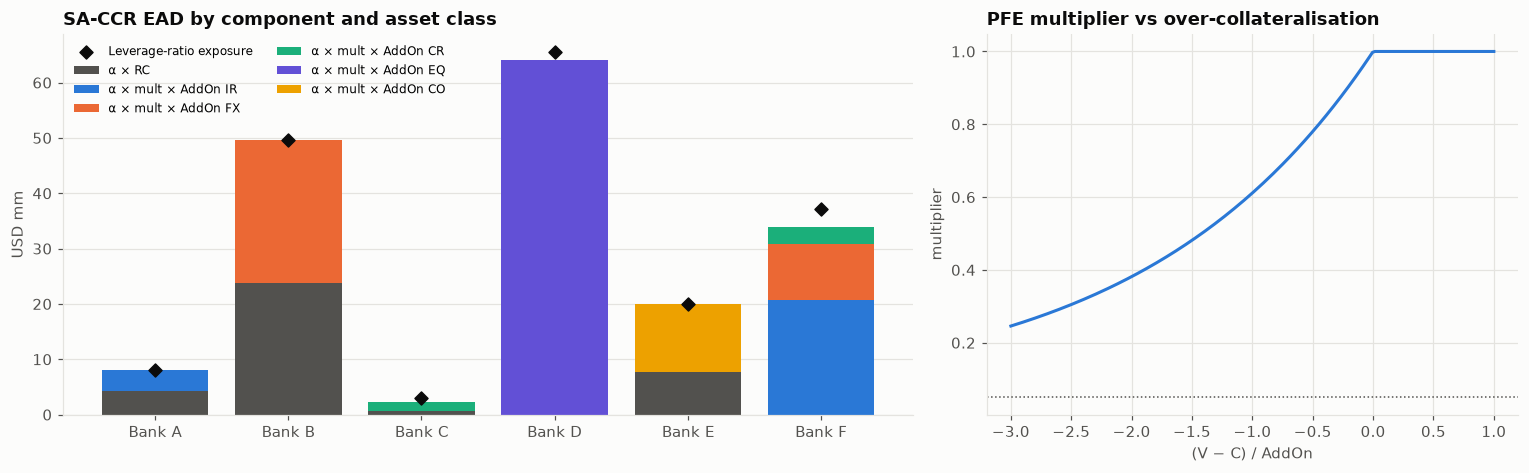

In [7]:
# --- Chart 1: what each netting set's EAD is made of, and the multiplier
fig, axes = plt.subplots(
    1, 2, figsize=(14, 4.4), gridspec_kw={"width_ratios": [1.6, 1]}
)
ax = axes[0]
bottom = ALPHA * ead_table["RC"]
ax.bar(ead_table.index, bottom, color=INK_2, label="α × RC")
for cls, color in CLASS_COLORS.items():
    h = ALPHA * ead_table["multiplier"] * ead_table[f"AddOn {cls}"]
    ax.bar(
        ead_table.index,
        h,
        bottom=bottom,
        color=color,
        label=f"α × mult × AddOn {cls}",
    )
    bottom = bottom + h
ax.scatter(
    ead_table.index,
    ead_table["leverage exposure"],
    marker="D",
    color=INK,
    zorder=3,
    label="Leverage-ratio exposure",
)
ax.set_title("SA-CCR EAD by component and asset class")
ax.set_ylabel("USD mm")
ax.legend(fontsize=8, ncol=2)
ax.grid(axis="x", visible=False)
ax = axes[1]
z = np.linspace(-3, 1, 200)
ax.plot(
    z, np.minimum(1, 0.05 + 0.95 * np.exp(z / (2 * 0.95))), color=PALETTE[0]
)
ax.axhline(0.05, color=INK_2, ls=":", lw=1)
ax.set_title("PFE multiplier vs over-collateralisation")
ax.set_xlabel("(V − C) / AddOn")
ax.set_ylabel("multiplier")
plt.tight_layout()
save_fig(fig, "01_saccr_ead_breakdown")
plt.show()

## 6. The internal model: Monte Carlo EEPE for rates and FX

For the comparison we need an IMM-style EAD, $\alpha\times\text{EEPE}$, where EEPE is the time average over the first year (or the life of the netting set, if shorter) of the non-decreasing expected exposure. Two risk factors are simulated:

- **Rates:** Hull–White 1F, calibrated to the realised volatility of Treasury yields.
- **FX:** EURUSD, GBPUSD and USDJPY as correlated GBMs, with three years of realised volatility and correlation (FRED) and drift equal to the rate differential (SOFR curve vs €STR, SONIA and Japanese 3-month rates).

Rates and FX are simulated independently, a simplification noted in the limitations. Margined netting sets use the Classical+ collateral model: a zero-threshold CSA with a 10-day MPoR.

In [8]:
TREASURY_URL = (
    "https://home.treasury.gov/resource-center/data-chart-center/interest-rates/"
    "daily-treasury-rates.csv/{year}/all?type=daily_treasury_yield_curve"
    "&field_tdr_date_value={year}&page&_format=csv"
)


def tenor_in_years(c):
    m = re.match(r"^\s*([\d.]+)\s*(Mo|Month|Yr|Year)", c)
    return (
        None
        if not m
        else float(m.group(1)) / (12 if m.group(2).startswith("Mo") else 1)
    )


def fetch_treasury_par():
    year = dt.date.today().year
    raw = pd.read_csv(
        io.StringIO(
            requests.get(
                TREASURY_URL.format(year=year),
                headers=BROWSER_HEADERS,
                timeout=30,
            ).text
        )
    )
    if raw.empty:
        raw = pd.read_csv(
            io.StringIO(
                requests.get(
                    TREASURY_URL.format(year=year - 1),
                    headers=BROWSER_HEADERS,
                    timeout=30,
                ).text
            )
        )
    raw["date"] = pd.to_datetime(raw["Date"], format="%m/%d/%Y")
    cols = {
        c: tenor_in_years(c)
        for c in raw.columns
        if tenor_in_years(c) is not None
    }
    long = raw.melt(
        id_vars="date",
        value_vars=list(cols),
        var_name="column",
        value_name="par_yield",
    )
    long["tenor"] = long["column"].map(cols)
    return long[["date", "tenor", "par_yield"]].dropna()


par_curves = cached("treasury_par_curves", fetch_treasury_par).pivot(
    index="date", columns="tenor", values="par_yield"
)
EVAL_DATE = par_curves.index.max()
par_today = par_curves.loc[EVAL_DATE].dropna()

VOL_SERIES = {
    "DGS1": 1,
    "DGS2": 2,
    "DGS3": 3,
    "DGS5": 5,
    "DGS7": 7,
    "DGS10": 10,
    "DGS20": 20,
    "DGS30": 30,
}


def fetch_vol_history():
    frames = [
        pd.DataFrame({"date": s.index, "tenor": tenor, "yield": s.values})
        for sid, tenor in VOL_SERIES.items()
        for s in [
            fred.get_series(
                sid, observation_start=EVAL_DATE - pd.Timedelta(days=3 * 365)
            ).dropna()
        ]
    ]
    sofr = fred.get_series(
        "SOFR", observation_start=EVAL_DATE - pd.Timedelta(days=30)
    ).dropna()
    frames.append(
        pd.DataFrame({"date": sofr.index, "tenor": 0.0, "yield": sofr.values})
    )
    return pd.concat(frames, ignore_index=True)


hist = (
    cached("fred_vol_history", fetch_vol_history)
    .pivot(index="date", columns="tenor", values="yield")
    .sort_index()
)
SOFR_TODAY = hist[0.0].dropna().iloc[-1] / 100
yields_hist = hist.drop(columns=0.0).dropna()

# --- Treasury zero curve with QuantLib, then SOFR = Treasury zero + swap
# spread
today = EVAL_DATE.normalize()
ql_today = ql.Date(today.day, today.month, today.year)
ql.Settings.instance().evaluationDate = ql_today
US_GOVT = ql.UnitedStates(ql.UnitedStates.GovernmentBond)
helpers, bond_dc = [], ql.ActualActual(ql.ActualActual.Bond)
for tenor, par_yield in par_today.items():
    y = par_yield / 100
    period = (
        ql.Period(int(round(tenor * 52)), ql.Weeks)
        if tenor < 1
        else ql.Period(int(round(tenor * 12)), ql.Months)
    )
    freq, cpns, px = (
        (ql.Once, [0.0], 100 / (1 + y / 2) ** (2 * tenor))
        if tenor <= 1
        else (ql.Semiannual, [y], 100.0)
    )
    sched = ql.Schedule(
        ql_today,
        US_GOVT.advance(ql_today, period),
        ql.Period(freq),
        US_GOVT,
        ql.Unadjusted,
        ql.Unadjusted,
        ql.DateGeneration.Backward,
        False,
    )
    helpers.append(
        ql.FixedRateBondHelper(
            ql.QuoteHandle(ql.SimpleQuote(px)), 0, 100.0, sched, cpns, bond_dc
        )
    )
ust_curve = ql.PiecewiseConvexMonotoneForward(
    ql_today, helpers, ql.Actual365Fixed()
)
ust_curve.enableExtrapolation()

FINE_T = np.linspace(0, 32, 32 * 365 + 1)
ust_z = np.array(
    [ust_curve.zeroRate(max(t, 1e-4), ql.Continuous).rate() for t in FINE_T]
)
# SOFR OIS minus Treasury par (bp): an explicit, documented swap-spread
# assumption
SWAP_SPREAD_BP = {2: -15, 3: -20, 5: -25, 7: -30, 10: -40, 20: -65, 30: -75}
spread_curve = np.interp(
    FINE_T, list(SWAP_SPREAD_BP), np.array(list(SWAP_SPREAD_BP.values())) / 1e4
)


class DiscountCurve:
    """
    A SOFR discount curve stored as continuous zero rates on a fine daily grid.
    """

    def __init__(self, zero):
        self.zero = np.asarray(zero, dtype=float)
        self.log_df = -self.zero * FINE_T

    def P0(self, t):
        """Discount factor P^M(0, t)."""
        return np.exp(np.interp(t, FINE_T, self.log_df))

    def f0(self, t, h=1e-4):
        """Instantaneous forward rate f^M(0, t)."""
        lo = np.maximum(np.asarray(t) - h, 0)
        return -(np.log(self.P0(np.asarray(t) + h)) - np.log(self.P0(lo))) / (
            np.asarray(t) + h - lo
        )

    def zero_rate(self, t):
        return np.interp(t, FINE_T, self.zero)

    def shifted(self, shift):
        """
        New curve with zero rates moved by `shift` (decimal): a number or an
        array on FINE_T.
        """
        return DiscountCurve(self.zero + shift)


CURVE = DiscountCurve(ust_z + spread_curve)
print(
    f"Evaluation date {today:%Y-%m-%d} · SOFR fixing {SOFR_TODAY*100:.2f}% ·"
    f" SOFR zero 2Y {CURVE.zero_rate(2)*100:.2f}% / 10Y"
    f" {CURVE.zero_rate(10)*100:.2f}%"
)

Evaluation date 2026-10-16 · SOFR fixing 3.88% · SOFR zero 2Y 4.54% / 10Y 4.66%


In [9]:
# bp per year, by tenor
realised_vol_bp = yields_hist.diff().dropna().std() * np.sqrt(252) * 100
vol_tenors = realised_vol_bp.index.to_numpy(dtype=float)


def model_vol_bp(params, tau):
    a, sigma = params
    return sigma * (1 - np.exp(-a * tau)) / (a * tau) * 1e4


fit = least_squares(
    lambda p: model_vol_bp(p, vol_tenors) - realised_vol_bp.values,
    x0=[0.05, 0.01],
    bounds=([1e-3, 1e-4], [1.0, 0.05]),
)
A_HW, SIGMA_HW = fit.x
print(
    "Hull–White calibrated to 3 years of realised Treasury volatility: a ="
    f" {A_HW:.4f}, sigma = {SIGMA_HW*1e4:.1f} bp/yr (fit RMSE"
    f" {np.sqrt(np.mean(fit.fun**2)):.1f} bp)"
)

Hull–White calibrated to 3 years of realised Treasury volatility: a = 0.0047, sigma = 86.7 bp/yr (fit RMSE 8.7 bp)


In [10]:
class HullWhite:
    """
    Hull–White 1F (G1++ form): r_t = x_t + phi(t), fitted exactly to `curve`.
    """

    def __init__(self, curve, a, sigma):
        self.curve, self.a, self.sigma = curve, a, sigma

    def B(self, t, T):
        return (1 - np.exp(-self.a * (T - t))) / self.a

    def V(self, t, T):
        a, tau = self.a, T - t
        return (
            self.sigma**2
            / a**2
            * (
                tau
                + 2 / a * np.exp(-a * tau)
                - np.exp(-2 * a * tau) / (2 * a)
                - 3 / (2 * a)
            )
        )

    def simulate(self, times, n_paths, seed):
        """
        Exact OU simulation on any increasing grid that starts at 0; also
        integrates r for SOFR accrual.
        """
        times = np.asarray(times, dtype=float)
        rng = np.random.default_rng(seed)
        x = np.zeros((n_paths, len(times)))
        for j in range(1, len(times)):
            d = times[j] - times[j - 1]
            sd = self.sigma * np.sqrt(
                (1 - np.exp(-2 * self.a * d)) / (2 * self.a)
            )
            x[:, j] = x[:, j - 1] * np.exp(
                -self.a * d
            ) + sd * rng.standard_normal(n_paths)
        phi = (
            self.curve.f0(times)
            + self.sigma**2
            / (2 * self.a**2)
            * (1 - np.exp(-self.a * times)) ** 2
        )
        r = x + phi
        int_r = np.concatenate(
            [
                np.zeros((n_paths, 1)),
                np.cumsum(
                    0.5 * (r[:, 1:] + r[:, :-1]) * np.diff(times), axis=1
                ),
            ],
            axis=1,
        )
        return {
            "times": times,
            "x": x,
            "int_r": int_r,
            "index": {round(t, 8): j for j, t in enumerate(times)},
        }

    def zcb(self, t, T, x_t):
        """
        P(t, T) on every path (x_t: paths) for every maturity in T (m) → paths
        × m.
        """
        T = np.atleast_1d(T)
        P0 = self.curve.P0
        log_a = np.log(P0(T) / P0(t)) + 0.5 * (
            self.V(t, T) - self.V(0.0, T) + self.V(0.0, t)
        )
        return np.exp(log_a[None, :] - np.outer(x_t, self.B(t, T)))


def par_rate(curve, first_pay, n):
    """
    Par fixed rate today for annual payments at first_pay, first_pay+1, ...;
    the part of the current
    period already elapsed accrues at today's SOFR fixing, exactly as in the
    simulation.
    """
    pay = first_pay + np.arange(n)
    start = first_pay - 1
    float_leg = (
        (np.exp(SOFR_TODAY * (-start)) - curve.P0(pay[-1]))
        if start < 0
        else curve.P0(start) - curve.P0(pay[-1])
    )
    return float_leg / curve.P0(pay).sum()


def swap_legs(first_pay, n_pay, hw, sim, dtype=np.float32, cutoff=None):
    """
    Annuity and floating-leg value per unit notional of an annual-fixed vs
    compounded-SOFR swap,
    on every path and simulation date (paths × dates). Value to the fixed
    receiver = K·annuity − float.
    `cutoff` (optional, one time per grid date) drops cash flows paid on or
    before it: used to value at
    t−MPoR only the flows still outstanding at t (both parties keep paying
    during the margin period).
    """
    times, x, int_r, index = sim["times"], sim["x"], sim["int_r"], sim["index"]
    cutoff = times if cutoff is None else np.maximum(cutoff, times)
    pay = first_pay + np.arange(n_pay)
    annuity = np.zeros(x.shape, dtype=dtype)
    float_leg = np.zeros(x.shape, dtype=dtype)
    for j, t in enumerate(times):
        live = pay > cutoff[j] + 1e-9
        if not live.any():
            # matured (or all flows paid by the cutoff)
            continue
        rem = pay[live]
        # start of the accrual period of the next flow
        start = rem[0] - 1.0
        # period starts after t (only with a cutoff)
        if start > t + 1e-9:
            p = hw.zcb(t, np.concatenate([[start], rem]), x[:, j])
            annuity[:, j] = p[:, 1:].sum(axis=1)
            float_leg[:, j] = p[:, 0] - p[:, -1]
            continue
        p = hw.zcb(t, rem, x[:, j])
        accrual = (
            np.exp(int_r[:, j] - int_r[:, index[round(start, 8)]])
            if start >= 0
            else np.exp(SOFR_TODAY * (-start) + int_r[:, j])
        )
        annuity[:, j] = p.sum(axis=1)
        # Compounded SOFR: the running coupon is worth (SOFR accrued so far) −
        # P(t, T_next), because the compounding still to come up to T_next is
        # worth exactly 1 today. Summing the remaining coupons telescopes to:
        # accrued factor − P(t, T_n).
        float_leg[:, j] = accrual - p[:, -1]
    return annuity, float_leg


def revalue_book(book, hw, sim, cutoff=None):
    """
    Values to us (USD mm) of every swap in `book` on every path and date →
    trades × paths × dates.
    """
    out = np.zeros((len(book), *sim["x"].shape), dtype=np.float32)
    for i, tr in enumerate(book.itertuples()):
        ann, flt = swap_legs(tr.first_pay, tr.n_pay, hw, sim, cutoff=cutoff)
        out[i] = tr.omega * (tr.fixed_rate * ann - flt) * tr.notional_mm
    return out


def exposure_metrics(v, times, q=0.975):
    """
    v: paths × monthly dates (USD mm) → EE, ENE, PFE profiles and the Basel
    1-year scalars EPE and EEPE
    (standard definitions: averages over the monthly grid points of the first
    year).
    """
    pos = np.maximum(v, 0)
    ee = pos.mean(axis=0)
    one_year = times <= 1.0 + 1e-9
    eff_ee = np.maximum.accumulate(ee)
    return {
        "EE": ee,
        "ENE": np.minimum(v, 0).mean(axis=0),
        "PFE": np.quantile(pos, q, axis=0),
        "EPE": ee[one_year].mean(),
        "EEPE": eff_ee[one_year].mean(),
    }

In [11]:
FX_SERIES = {
    "EURUSD": ("DEXUSEU", False),
    "GBPUSD": ("DEXUSUK", False),
    "USDJPY": ("DEXJPUS", True),
}
FOREIGN_RATE = {
    "EURUSD": "ECBESTRVOLWGTTRMDMNRT",
    "GBPUSD": "IUDSOIA",
    "USDJPY": "IR3TIB01JPM156N",
}


def fetch_fx():
    frames = []
    for pair, (sid, _) in FX_SERIES.items():
        s = fred.get_series(
            sid, observation_start=EVAL_DATE - pd.Timedelta(days=3 * 365)
        ).dropna()
        frames.append(
            pd.DataFrame({"date": s.index, "series": pair, "value": s.values})
        )
    for pair, sid in FOREIGN_RATE.items():
        s = fred.get_series(
            sid, observation_start=EVAL_DATE - pd.Timedelta(days=365)
        ).dropna()
        frames.append(
            pd.DataFrame(
                {"date": s.index, "series": f"rate_{pair}", "value": s.values}
            )
        )
    return pd.concat(frames, ignore_index=True)


fx_raw = (
    cached("fred_fx", fetch_fx)
    .pivot(index="date", columns="series", values="value")
    .sort_index()
)
# Express every pair as USD per unit of foreign currency (JPY quoted per USD is
# inverted)
fx = pd.DataFrame({
    p: 1 / fx_raw[p] if inv else fx_raw[p] for p, (_, inv) in FX_SERIES.items()
}).dropna()
fx_ret = np.log(fx).diff().dropna()
FX_VOL = fx_ret.std() * np.sqrt(252)
FX_CORR = fx_ret.corr()
SPOT = fx.iloc[-1]
R_FOREIGN = pd.Series(
    {p: fx_raw[f"rate_{p}"].dropna().iloc[-1] / 100 for p in FX_SERIES}
)
display(
    pd.DataFrame({
        "spot (USD per unit)": SPOT,
        "vol 3y": FX_VOL,
        "foreign rate": R_FOREIGN,
    }).round(4)
)
FX_CORR.round(2)

,spot (USD per unit),vol 3y,foreign rate
EURUSD,1.12,0.07,0.02
GBPUSD,1.32,0.07,0.04
USDJPY,0.01,0.10,0.02


,EURUSD,GBPUSD,USDJPY
EURUSD,1.00,0.81,0.56
GBPUSD,0.81,1.00,0.49
USDJPY,0.56,0.49,1.00


In [12]:
# --- Simulation grid: monthly to one year, plus the 10-day lag dates
MONTHLY = np.round(np.arange(0, 1 + DT / 2, DT), 10)
LAG = np.round(np.maximum(MONTHLY - MPOR_DAYS / 252, 0.0), 10)
GRID = np.unique(np.concatenate([MONTHLY, LAG]))
I_NOW, I_LAG = np.searchsorted(GRID, MONTHLY), np.searchsorted(GRID, LAG)
CUTOFF = GRID.copy()
CUTOFF[I_LAG] = np.maximum(CUTOFF[I_LAG], MONTHLY)

hw = HullWhite(CURVE, A_HW, SIGMA_HW)
sim = hw.simulate(GRID, N_PATHS, seed=SEED)

# Correlated GBM for FX (independent of the rates factor)
fx_rng = np.random.default_rng(SEED + 1)
chol = np.linalg.cholesky(FX_CORR.values)
PAIRS = list(FX_SERIES)
log_s = np.zeros((len(PAIRS), N_PATHS, len(GRID)))
for j in range(1, len(GRID)):
    d = GRID[j] - GRID[j - 1]
    z = chol @ fx_rng.standard_normal((len(PAIRS), N_PATHS))
    for k, p in enumerate(PAIRS):
        r_d = CURVE.zero_rate(1.0)
        log_s[k, :, j] = (
            log_s[k, :, j - 1]
            + (r_d - R_FOREIGN[p] - 0.5 * FX_VOL[p] ** 2) * d
            + FX_VOL[p] * np.sqrt(d) * z[k]
        )
FX_PATHS = {p: SPOT[p] * np.exp(log_s[k]) for k, p in enumerate(PAIRS)}


def fx_legs(pair, T):
    """
    Per unit of foreign notional: spot leg S_t·e^{-r_f(T-t)} and cash leg
    e^{-r_d(T-t)} (paths × grid).
    Classical+ cut-off: a forward settling on or before an exposure date is
    gone at its lag date too.
    """
    tau = np.maximum(T - GRID, 0.0)
    alive = (T > CUTOFF + 1e-9).astype(float)
    spot_leg = FX_PATHS[pair] * np.exp(-R_FOREIGN[pair] * tau) * alive
    cash_leg = (CURVE.P0(T) / CURVE.P0(GRID)) * alive
    return spot_leg.astype(np.float32), np.broadcast_to(
        cash_leg, spot_leg.shape
    ).astype(np.float32)


def imm_ead(v, maturity, margined=False):
    """
    α × EEPE from paths × grid values; EEPE averaged over min(1 year, longest
    maturity).
    """
    v_now = v[:, I_NOW]
    # zero-threshold CSA, MTA 0.5mm, collateral from t − MPoR
    if margined:
        v_lag = v[:, I_LAG]
        e = v_now - np.maximum(v_lag - 0.5, 0) + np.maximum(-v_lag - 0.5, 0)
    else:
        e = v_now
    ee = np.maximum(e, 0).mean(axis=0)
    horizon = MONTHLY <= min(1.0, maturity) + 1e-9
    return ALPHA * np.maximum.accumulate(ee)[horizon].mean()


print(
    f"IMM engine ready: {N_PATHS:,} paths × {len(GRID)} dates · FX vols "
    + ", ".join(f"{p} {FX_VOL[p]*100:.1f}%" for p in PAIRS)
)

IMM engine ready: 5,000 paths × 25 dates · FX vols EURUSD 6.7%, GBPUSD 6.8%, USDJPY 9.8%


## 7. SA-CCR vs IMM on 1,500 random netting sets

Every netting set is a random mix of 2–10 trades drawn from SOFR swaps (1–30 years, new or seasoned) and FX forwards (3 months to 2 years), with random direction and size. Both the swaps and the forwards are linear in notional and strike, so each template is simulated once and every design is an exact weighted sum. The same netting set then goes through both engines:

- **SA-CCR:** trades mapped to the standard fields (swap: $S=0$, $E=M=$ residual maturity, $\delta=+1$ when paying fixed; FX forward: USD notional of the foreign leg, $\delta=+1$ when long the foreign currency).
- **IMM:** $\alpha\times$EEPE from the simulation.

Both are computed unmargined and under a zero-threshold CSA (MTA 0.5mm, 10-day MPoR, VM equal to today's MtM).

In [13]:
IR_TEMPLATES = [
    (fp, n) for n in (1, 2, 3, 5, 7, 10, 15, 20, 30) for fp in (1.0, 0.5)
]
FX_TEMPLATES = [(p, T) for p in PAIRS for T in (0.25, 0.5, 1.0, 2.0)]
ir_legs = [swap_legs(fp, n, hw, sim, cutoff=CUTOFF) for fp, n in IR_TEMPLATES]
ir_par = np.array([par_rate(CURVE, fp, n) for fp, n in IR_TEMPLATES])
fxl = [fx_legs(p, T) for p, T in FX_TEMPLATES]
fx_fwd = np.array([
    SPOT[p] * np.exp((CURVE.zero_rate(T) - R_FOREIGN[p]) * T)
    for p, T in FX_TEMPLATES
])

design_rng = np.random.default_rng(SEED + 5)
records = []
t0 = time.perf_counter()
for _ in range(N_DESIGNS):
    k = int(design_rng.integers(2, 11))
    fx_share = design_rng.choice([0.0, 0.0, 0.3, 0.5, 1.0])
    v = np.zeros((N_PATHS, len(GRID)), dtype=np.float32)
    rows, gross, maturity = [], 0.0, 0.0
    for _ in range(k):
        size = float(design_rng.choice([25, 50, 100, 200, 300, 500]))
        sign = float(design_rng.choice([-1.0, 1.0]))
        seasoned = design_rng.random() < 0.6
        if design_rng.random() < fx_share:
            i = int(design_rng.integers(len(FX_TEMPLATES)))
            pair, T = FX_TEMPLATES[i]
            K = fx_fwd[i] * (
                1 + (design_rng.normal(0, 0.04) if seasoned else 0.0)
            )
            # foreign notional (mm units)
            nf = size / SPOT[pair]
            leg_s, leg_c = fxl[i]
            vi = sign * nf * (leg_s - K * leg_c)
            rows.append({
                "asset_class": "FX",
                "sub": pair,
                "notional": size,
                "M": T,
                "E": T,
                "direction": sign,
                "mtm": float(vi[:, 0].mean()),
            })
            maturity = max(maturity, T)
        else:
            i = int(design_rng.integers(len(IR_TEMPLATES)))
            fp, n = IR_TEMPLATES[i]
            K = ir_par[i] + (design_rng.normal(0, 0.0075) if seasoned else 0.0)
            ann, flt = ir_legs[i]
            # sign = +1 → pay fixed (long rates)
            vi = -sign * (K * ann - flt) * size
            mat = fp + n - 1
            rows.append({
                "asset_class": "IR",
                "sub": "USD",
                "notional": size,
                "M": mat,
                "E": mat,
                "direction": sign,
                "mtm": float(vi[:, 0].mean()),
            })
            maturity = max(maturity, mat)
        v += vi
        gross += size
    trades = make_trades(rows)
    sa_u = saccr(trades)
    sa_m = saccr(
        trades,
        collateral=trades["mtm"].sum(),
        margined=True,
        th=0,
        mta=0.5,
        mpor_days=MPOR_DAYS,
    )
    D = trade_level(trades)["D"]
    records.append({
        "n_trades": k,
        "fx_share": (trades["asset_class"] == "FX").mul(
            trades["notional"]
        ).sum() / gross,
        "direction_balance": abs(D.sum()) / D.abs().sum(),
        "wavg_maturity": np.average(trades["M"], weights=trades["notional"]),
        "mtm_rel": trades["mtm"].sum() / gross * 100,
        "gross_notional": gross,
        "saccr_unmargined": sa_u["EAD"],
        "imm_unmargined": imm_ead(v, maturity),
        "saccr_margined": sa_m["EAD"],
        "imm_margined": imm_ead(v, maturity, margined=True),
    })
cmp_df = pd.DataFrame(records)
cmp_df["ratio_unmargined"] = (
    cmp_df["saccr_unmargined"] / cmp_df["imm_unmargined"]
)
cmp_df["ratio_margined"] = cmp_df["saccr_margined"] / cmp_df["imm_margined"]
# Deep out-of-the-money netting sets have (almost) no IMM exposure, while
# SA-CCR keeps 5% of the add-on through the multiplier floor: the ratio is
# meaningless there, so they are reported separately.
cmp_df["valid"] = (cmp_df["imm_unmargined"] > 0.5) & (
    cmp_df["imm_margined"] > 0.05
)
floor_cases = cmp_df[~cmp_df["valid"]]
cmp = cmp_df[cmp_df["valid"]].copy()
print(
    f"{len(cmp_df):,} netting sets through both engines in"
    f" {time.perf_counter() - t0:.0f}s · {len(floor_cases)} deep"
    " out-of-the-money sets (IMM ≈ 0, SA-CCR held up by the multiplier floor:"
    f" median MtM {floor_cases['mtm_rel'].median():.1f}% of notional) set"
    " aside"
)
cmp[["ratio_unmargined", "ratio_margined"]].describe(
    percentiles=[0.1, 0.5, 0.9]
).T.round(2)

1,500 netting sets through both engines in 27s · 117 deep out-of-the-money sets (IMM ≈ 0, SA-CCR held up by the multiplier floor: median MtM -2.1% of notional) set aside


,count,mean,std,min,10%,50%,90%,max
ratio_unmargined,"1,383.00",3.13,2.71,0.21,1.52,2.35,5.26,33.53
ratio_margined,"1,383.00",2.94,0.94,0.48,2.16,2.70,4.08,12.86


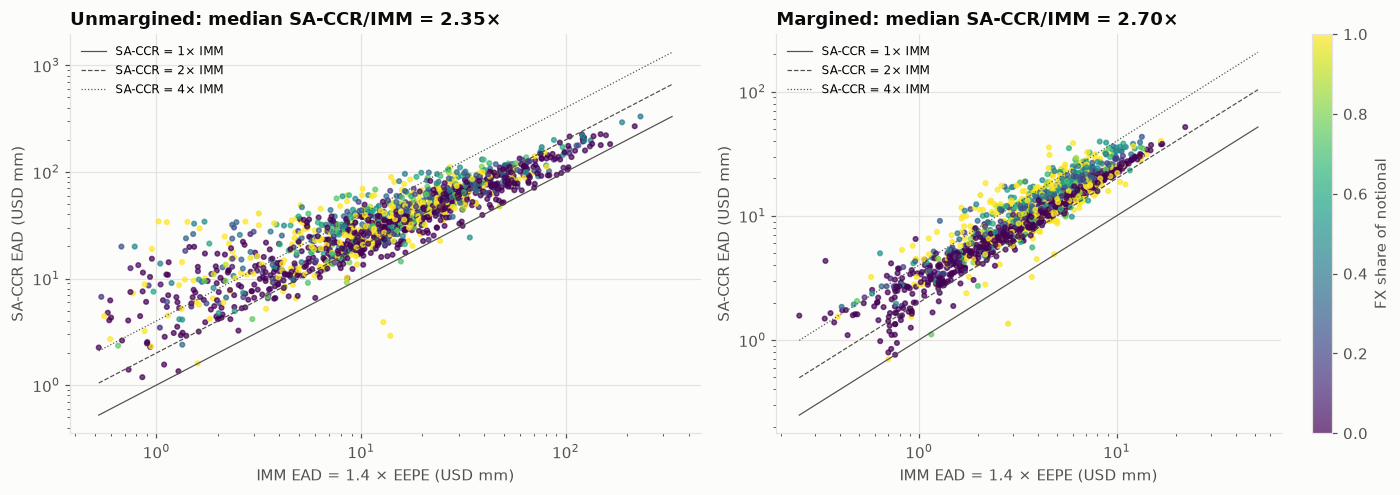

In [14]:
# --- Chart 2: SA-CCR vs IMM EAD
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
for ax, kind in zip(axes, ["unmargined", "margined"]):
    x_, y_ = cmp[f"imm_{kind}"], cmp[f"saccr_{kind}"]
    sc = ax.scatter(x_, y_, c=cmp["fx_share"], cmap="viridis", s=9, alpha=0.7)
    lim = [max(min(x_.min(), y_.min()), 1e-2), max(x_.max(), y_.max())]
    for mult, ls in [(1, "-"), (2, "--"), (4, ":")]:
        ax.plot(
            lim,
            np.array(lim) * mult,
            color=INK_2,
            lw=0.8,
            ls=ls,
            label=f"SA-CCR = {mult}× IMM",
        )
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_title(
        f"{kind.capitalize()}: median SA-CCR/IMM ="
        f" {cmp[f'ratio_{kind}'].median():.2f}×"
    )
    ax.set_xlabel("IMM EAD = 1.4 × EEPE (USD mm)")
    ax.set_ylabel("SA-CCR EAD (USD mm)")
    ax.legend(fontsize=8, loc="upper left")
plt.colorbar(sc, ax=axes[1], label="FX share of notional")
plt.tight_layout()
save_fig(fig, "02_saccr_vs_imm_scatter")
plt.show()

## 8. Where is SA-CCR most conservative? Quantile regression

The ratio is skewed and its spread differs across books, so a mean regression would hide the useful part. Linear quantile regression at the 10th, 50th and 90th percentiles of $\log(\text{SA-CCR}/\text{IMM})$ shows how each portfolio feature shifts the typical ratio and the tails. For example, a feature that only raises the 90th percentile flags books where SA-CCR can be dramatically punitive.

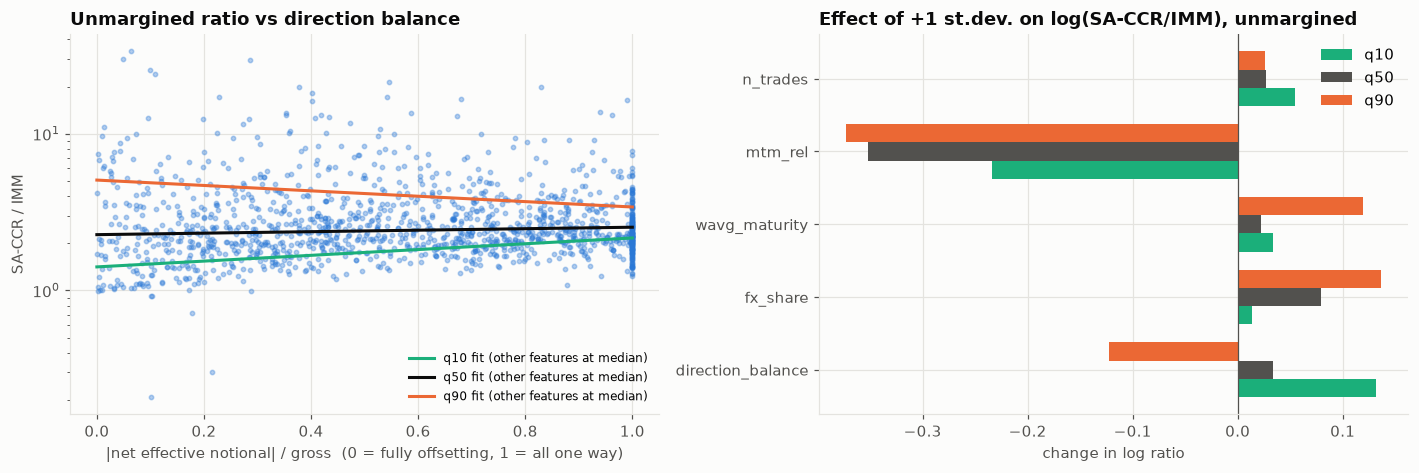

log_ratio                                  log_ratio_m  \
                       0.10  p 0.1  0.50  p 0.5  0.90  p 0.9        0.10   
intercept              0.19   0.00  0.71   0.00  1.40   0.00        0.64   
direction_balance      0.42   0.00  0.11   0.00 -0.40   0.00        0.11   
fx_share               0.03   0.30  0.19   0.00  0.33   0.00        0.00   
wavg_maturity          0.01   0.02  0.00   0.04  0.02   0.00        0.00   
mtm_rel               -0.10   0.00 -0.15   0.00 -0.16   0.00       -0.02   
n_trades               0.02   0.00  0.01   0.00  0.01   0.29        0.01   

                                                    
                   p 0.1  0.50  p 0.5  0.90  p 0.9  
intercept           0.00  1.11   0.00  1.59   0.00  
direction_balance   0.00 -0.16   0.00 -0.38   0.00  
fx_share            0.89  0.15   0.00  0.29   0.00  
wavg_maturity       0.15 -0.00   0.27 -0.01   0.00  
mtm_rel             0.00 -0.02   0.00 -0.01   0.17  
n_trades            0.00 -0.01   0.00 -0.01   0.03

In [15]:
reg = cmp.assign(
    log_ratio=np.log(cmp["ratio_unmargined"]),
    log_ratio_m=np.log(cmp["ratio_margined"]),
)
formula = "~ direction_balance + fx_share + wavg_maturity + mtm_rel + n_trades"
QUANTS = [0.1, 0.5, 0.9]
coef = {}
for target in ["log_ratio", "log_ratio_m"]:
    for q in QUANTS:
        fit_q = smf.quantreg(target + formula, reg).fit(q=q)
        coef[(target, q)] = fit_q.params.rename(
            lambda n: n.replace("Intercept", "intercept")
        )
        coef[(target, f"p {q}")] = fit_q.pvalues.rename(
            lambda n: n.replace("Intercept", "intercept")
        )
coef = pd.DataFrame(coef)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.4))
ax = axes[0]
ax.scatter(
    reg["direction_balance"],
    reg["ratio_unmargined"],
    s=8,
    color=PALETTE[0],
    alpha=0.35,
)
grid_b = np.linspace(0, 1, 50)
base = reg[["fx_share", "wavg_maturity", "mtm_rel", "n_trades"]].median()
for q, color in zip(QUANTS, [PALETTE[2], INK, PALETTE[1]]):
    b = coef[("log_ratio", q)]
    yhat = (
        b["intercept"]
        + b["direction_balance"] * grid_b
        + sum(b[f] * base[f] for f in base.index)
    )
    ax.plot(
        grid_b,
        np.exp(yhat),
        color=color,
        lw=2,
        label=f"q{int(q*100)} fit (other features at median)",
    )
ax.set_yscale("log")
ax.set_title("Unmargined ratio vs direction balance")
ax.set_xlabel(
    "|net effective notional| / gross  (0 = fully offsetting, 1 = all one way)"
)
ax.set_ylabel("SA-CCR / IMM")
ax.legend(fontsize=8)
ax = axes[1]
feats = [
    "direction_balance",
    "fx_share",
    "wavg_maturity",
    "mtm_rel",
    "n_trades",
]
# effect of a one-standard-deviation move
scale = reg[feats].std()
xp = np.arange(len(feats))
for k, (q, color) in enumerate(zip(QUANTS, [PALETTE[2], INK_2, PALETTE[1]])):
    ax.barh(
        xp + (k - 1) * 0.25,
        coef[("log_ratio", q)][feats] * scale,
        0.25,
        color=color,
        label=f"q{int(q*100)}",
    )
ax.set_yticks(xp, feats)
ax.axvline(0, color=INK_2, lw=0.8)
ax.set_title("Effect of +1 st.dev. on log(SA-CCR/IMM), unmargined")
ax.set_xlabel("change in log ratio")
ax.legend()
plt.tight_layout()
save_fig(fig, "03_quantile_regression_ratio")
plt.show()
cmp_df.to_csv(OUT_DIR / "saccr_vs_imm_designs.csv", index=False)
ead_table.to_csv(OUT_DIR / "saccr_multi_asset_ead.csv")
validation.to_csv(OUT_DIR / "saccr_basel_validation.csv")
coef.round(3)

## 9. Reading the results and limitations

These figures come from the run of 16 October 2026 on 1,383 comparable netting sets.

**SA-CCR is meant to be conservative, and it is.** The median SA-CCR/IMM ratio is about **2.4×** unmargined and **2.7×** margined, and 80% of unmargined books fall between about 1.5× and 5×.

Margined books show a tighter range (2.2×–4.1×) because both engines reduce to a short margin-period move. SA-CCR's margined maturity factor, $1.5\sqrt{10/250}=0.30$, is still generous compared with a 10-day diffusion.

**The shape of the book drives the tails, not the median.** The quantile regression shows three effects.

**Offsetting books** (low direction balance) have a much **wider upper tail**: the q90 coefficient is negative while the q10 coefficient is positive. SA-CCR allows only partial offset across maturity buckets, while a one-factor IMM nets a 2-year payer against a 10-year receiver almost perfectly.

Hedged books are where SA-CCR can be 5–10× the internal model. Part of that gap is model risk on the IMM side, which a multi-factor model would reduce.

**FX share** pushes the ratio up at the median and in the tail. The 4% supervisory factor is large next to the 7–10% realised FX volatility of the last three years.

**In-the-money books** (positive MtM) have lower ratios, because the replacement cost is the same in both engines and dilutes the difference in add-ons.

**Deep out-of-the-money books** (117 of 1,500) have almost no IMM exposure, yet keep an SA-CCR EAD through the 5% multiplier floor. This is a deliberate regulatory choice, and a pre-trade capital tool should show it explicitly.

**Leverage ratio.** Non-cash collateral does not reduce RC and the multiplier is 1, so Bank C (securities as VM) and the out-of-the-money netting sets show a leverage exposure above their SA-CCR EAD.

**Limitations**

- The IMM side covers rates and FX only, as independent factors, with a one-factor rates model that overstates offsetting between maturities. A real IMM has multi-factor curves, rates–FX correlation and stochastic credit.
- SA-CCR follows CRE52 with simplifications: no negative-rate shift $\lambda$ in option deltas, no basis or volatility transactions, no CDO tranches, and one netting set per counterparty.
- The multi-asset book and its MtMs are illustrative. Collateral haircuts, NICA and segregation rules are simplified.

## References

### Finance and regulation

- Basel Committee on Banking Supervision. (2014). *The standardised approach for measuring counterparty credit risk exposures*. Bank for International Settlements. https://www.bis.org/publ/bcbs279.htm
- Basel Committee on Banking Supervision. (2014). *Foundations of the standardised approach for measuring counterparty credit risk exposures* (Working Paper No. 26). Bank for International Settlements. https://www.bis.org/publ/bcbs_wp26.htm
- Basel Committee on Banking Supervision. (2017). *Basel III: Finalising post-crisis reforms*. Bank for International Settlements. https://www.bis.org/bcbs/publ/d424.htm
- Andersen, L., Pykhtin, M., & Sokol, A. (2017). Rethinking the margin period of risk. *Journal of Credit Risk, 13*(1), 1–45. https://doi.org/10.21314/JCR.2016.218
- Gregory, J. (2020). *The xVA challenge: Counterparty risk, funding, collateral, capital and initial margin* (4th ed.). Wiley. https://doi.org/10.1002/9781119508991
- Hull, J., & White, A. (1990). Pricing interest-rate-derivative securities. *The Review of Financial Studies, 3*(4), 573–592. https://doi.org/10.1093/rfs/3.4.573

### Machine learning and deep learning

- Koenker, R., & Bassett, G. (1978). Regression quantiles. *Econometrica, 46*(1), 33–50. https://doi.org/10.2307/1913643
- Koenker, R., & Hallock, K. F. (2001). Quantile regression. *Journal of Economic Perspectives, 15*(4), 143–156. https://doi.org/10.1257/jep.15.4.143
- Glasserman, P. (2004). *Monte Carlo methods in financial engineering*. Springer. https://doi.org/10.1007/978-0-387-21617-1